⏳ Loading Keras Architecture Graph...
✅ Segmentation-only sub-model ready.

🎬 Processing Specimen 1...
🏆 [SEG SUCCESS] Qualitative evaluation plot saved to: thesis_positive_result.png


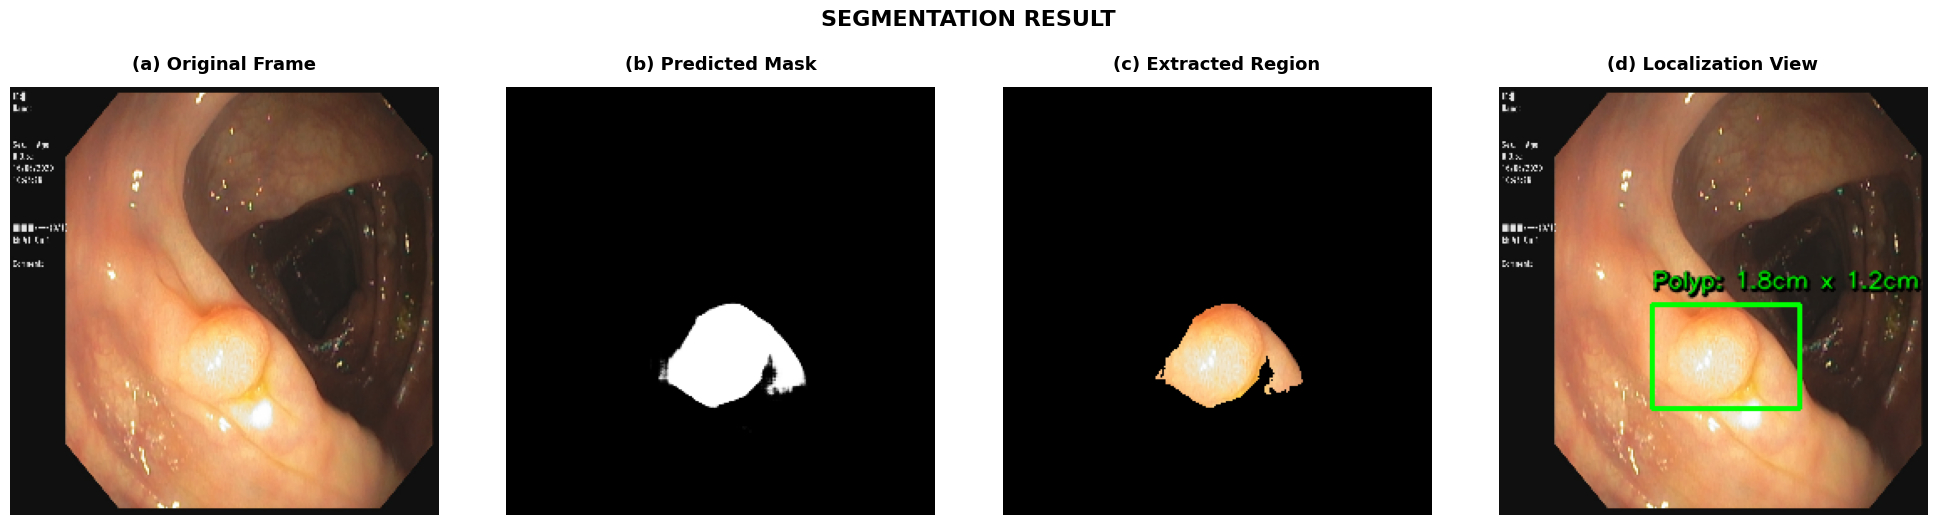

🧬 [GP SUCCESS] Genetic mask comparison saved to: thesis_positive_result_genetic.png
   • Fidelity-Focused     fitness=0.901  program=gaussian5(median3(median3(gaussian5(dilate5(erode5(mask))))))
   • Smoothness-Focused   fitness=0.775  program=median5(dilate5(open3(open3(mask))))
   • Balanced             fitness=0.788  program=open3(median3(median5(dilate5(open3(mask)))))
   • Compact-Region       fitness=0.639  program=close5(median5(close3(open5(dilate3(mask)))))


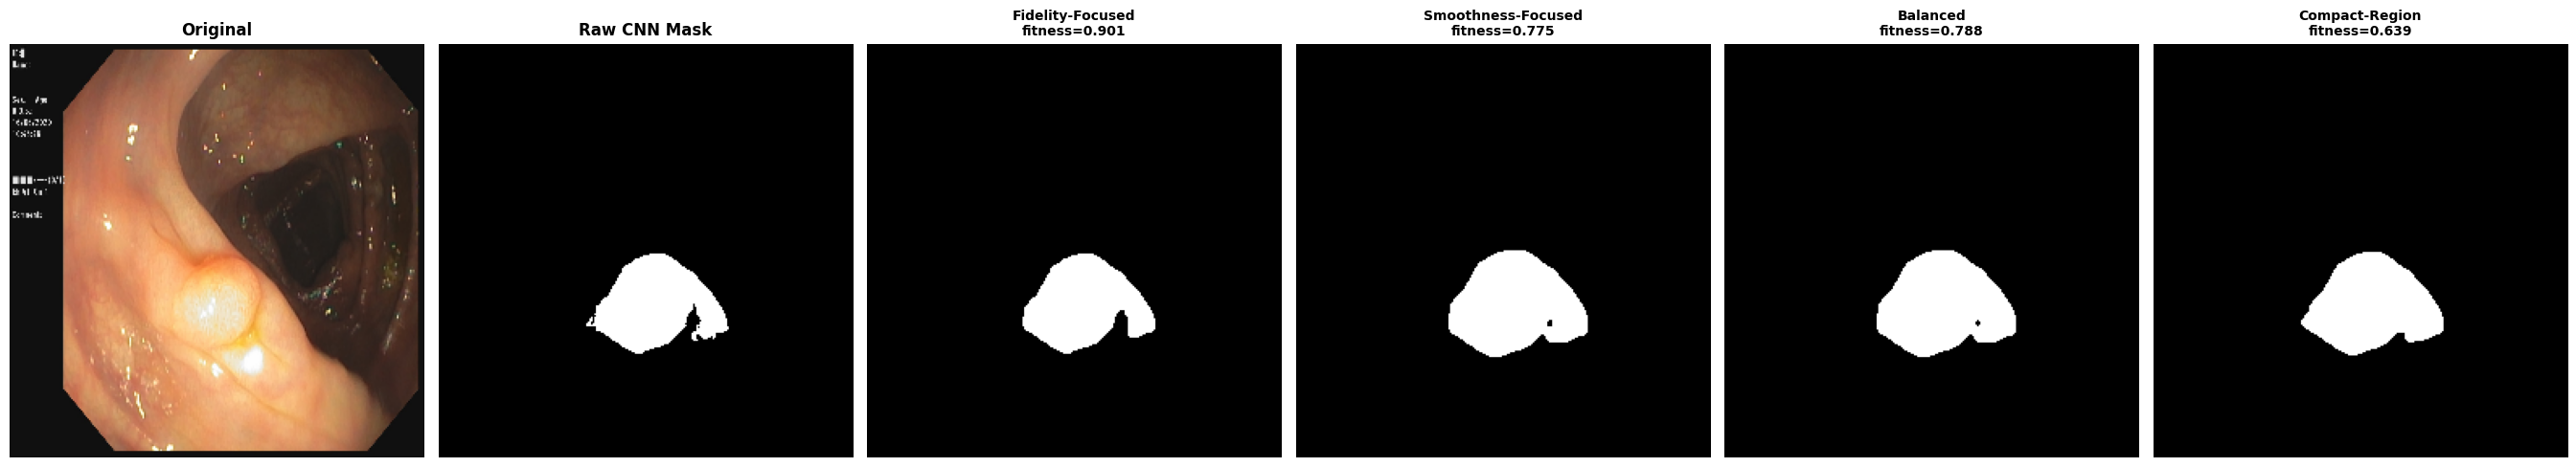

In [12]:
%matplotlib inline

import os
import cv2
import gc
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import keras
from deap import base, creator, tools, gp, algorithms

# ─────────────────────────────────────────────────────────────────────────────
# ⚙️ CONFIG
# ─────────────────────────────────────────────────────────────────────────────
IMG_SIZE = 256

MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"

TEST_IMAGES = [
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_0084.jpg",

]


# ─────────────────────────────────────────────────────────────────────────────
# 🧬 CUSTOM LAYER (self-contained লোডিং এর জন্য)
# ─────────────────────────────────────────────────────────────────────────────
@keras.saving.register_keras_serializable(package="Custom")
class KerasPCCLayer(keras.layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def call(self, inputs):
        x = inputs
        mean = tf.reduce_mean(x, axis=-1, keepdims=True)
        std = tf.math.reduce_std(x, axis=-1, keepdims=True) + 1e-7
        x_norm = (x - mean) / std
        outer = tf.matmul(tf.expand_dims(x_norm, axis=2), tf.expand_dims(x_norm, axis=1))
        batch = tf.shape(x)[0]
        c = tf.shape(x)[-1]
        return tf.reshape(outer, [batch, c * c])

    def compute_output_shape(self, input_shape):
        c = input_shape[-1]
        return (input_shape[0], c * c if c is not None else None)

    def get_config(self):
        return super().get_config()


# ─────────────────────────────────────────────────────────────────────────────
# 🎨 LOCALIZATION HELPER (শুধু সেগমেন্টেশনের ওপর ভিত্তি করে, ক্লাসিফিকেশন ছাড়াই)
# ─────────────────────────────────────────────────────────────────────────────
def draw_bounding_box(image, mask):
    res_img = image.copy()
    mask_uint8 = (mask > 0.5).astype(np.uint8) * 255
    contours, _ = cv2.findContours(mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    pixel_to_cm_ratio = 50
    for cnt in contours:
        if cv2.contourArea(cnt) < 10:
            continue
        x, y, w, h = cv2.boundingRect(cnt)
        width_cm = w / pixel_to_cm_ratio
        height_cm = h / pixel_to_cm_ratio
        size_text = f"Polyp: {width_cm:.1f}cm x {height_cm:.1f}cm"

        cv2.rectangle(res_img, (x, y), (x + w, y + h), (0, 255, 0), 2)
        text_y = y - 10 if y - 10 > 20 else y + h + 20
        cv2.putText(res_img, size_text, (x + 1, text_y + 1),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 2, cv2.LINE_AA)
        cv2.putText(res_img, size_text, (x, text_y),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 0), 1, cv2.LINE_AA)

    return res_img


# ─────────────────────────────────────────────────────────────────────────────
# 🧬 GENETIC PROGRAMMING MODULE — MULTI-MASK BOUNDARY REFINEMENT
# ─────────────────────────────────────────────────────────────────────────────
# একটাই টাইপ (mask) ব্যবহার করা হয়েছে — kernel size আলাদা টাইপ না রেখে প্রতিটা
# সাইজের জন্য আলাদা fixed-arity primitive বানানো হয়েছে (erode3, erode5 ইত্যাদি)।
# এতে DEAP-এর typed-GP int-terminal ক্র্যাশ (IndexError) সম্পূর্ণ এড়ানো যায়।
# ৪টা ভিন্ন fitness-profile দিয়ে ৪টা স্বতন্ত্র GP evolution রান করে ৪টা মাস্ক
# পাশাপাশি জেনারেট করা হয়।
# ─────────────────────────────────────────────────────────────────────────────

GP_POP_SIZE = 24
GP_NGEN = 8

GP_PROFILES = [
    {"name": "Fidelity-Focused",   "w_iou": 0.80, "w_circ": 0.20, "comp_penalty": 0.03},
    {"name": "Smoothness-Focused", "w_iou": 0.30, "w_circ": 0.70, "comp_penalty": 0.05},
    {"name": "Balanced",           "w_iou": 0.50, "w_circ": 0.50, "comp_penalty": 0.05},
    {"name": "Compact-Region",     "w_iou": 0.40, "w_circ": 0.40, "comp_penalty": 0.15},
]


def _morph(mask, op, k):
    kernel = np.ones((k, k), np.uint8)
    return cv2.morphologyEx(mask, op, kernel)


def op_erode3(mask):  return cv2.erode(mask, np.ones((3, 3), np.uint8))
def op_erode5(mask):  return cv2.erode(mask, np.ones((5, 5), np.uint8))
def op_dilate3(mask): return cv2.dilate(mask, np.ones((3, 3), np.uint8))
def op_dilate5(mask): return cv2.dilate(mask, np.ones((5, 5), np.uint8))
def op_open3(mask):   return _morph(mask, cv2.MORPH_OPEN, 3)
def op_open5(mask):   return _morph(mask, cv2.MORPH_OPEN, 5)
def op_close3(mask):  return _morph(mask, cv2.MORPH_CLOSE, 3)
def op_close5(mask):  return _morph(mask, cv2.MORPH_CLOSE, 5)
def op_median3(mask): return cv2.medianBlur(mask, 3)
def op_median5(mask): return cv2.medianBlur(mask, 5)

def op_gaussian3(mask):
    blurred = cv2.GaussianBlur(mask, (3, 3), 0)
    _, out = cv2.threshold(blurred, 127, 255, cv2.THRESH_BINARY)
    return out

def op_gaussian5(mask):
    blurred = cv2.GaussianBlur(mask, (5, 5), 0)
    _, out = cv2.threshold(blurred, 127, 255, cv2.THRESH_BINARY)
    return out

def op_keep_largest(mask):
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return mask
    out = np.zeros_like(mask)
    largest = max(contours, key=cv2.contourArea)
    cv2.drawContours(out, [largest], -1, 255, thickness=cv2.FILLED)
    return out

def op_fill_holes(mask):
    h, w = mask.shape
    flood = mask.copy()
    ff_mask = np.zeros((h + 2, w + 2), np.uint8)
    cv2.floodFill(flood, ff_mask, (0, 0), 255)
    flood_inv = cv2.bitwise_not(flood)
    return mask | flood_inv


# ── Single-type (untyped) GP primitive set: mask -> mask ──
pset = gp.PrimitiveSet("MASK_GP", 1)
pset.renameArguments(ARG0="mask")

_PRIMITIVES = [
    (op_erode3, "erode3"), (op_erode5, "erode5"),
    (op_dilate3, "dilate3"), (op_dilate5, "dilate5"),
    (op_open3, "open3"), (op_open5, "open5"),
    (op_close3, "close3"), (op_close5, "close5"),
    (op_median3, "median3"), (op_median5, "median5"),
    (op_gaussian3, "gaussian3"), (op_gaussian5, "gaussian5"),
    (op_keep_largest, "keep_largest"), (op_fill_holes, "fill_holes"),
]
for _func, _name in _PRIMITIVES:
    pset.addPrimitive(_func, 1, name=_name)

if not hasattr(creator, "GPFitnessMax"):
    creator.create("GPFitnessMax", base.Fitness, weights=(1.0,))
if not hasattr(creator, "GPIndividual"):
    creator.create("GPIndividual", gp.PrimitiveTree, fitness=creator.GPFitnessMax)


def eval_mask_program(individual, raw_mask_uint8, profile, compiler):
    func = compiler(expr=individual)
    try:
        candidate = func(raw_mask_uint8.copy())
    except Exception:
        return (-1.0,)

    if candidate is None or not isinstance(candidate, np.ndarray):
        return (-1.0,)
    candidate = (candidate > 127).astype(np.uint8) * 255
    if candidate.sum() == 0:
        return (-1.0,)

    inter = np.logical_and(candidate > 0, raw_mask_uint8 > 0).sum()
    union = np.logical_or(candidate > 0, raw_mask_uint8 > 0).sum()
    iou = inter / (union + 1e-7)

    contours, _ = cv2.findContours(candidate, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return (-1.0,)
    largest = max(contours, key=cv2.contourArea)
    area = cv2.contourArea(largest)
    perimeter = cv2.arcLength(largest, True)
    if area <= 0 or perimeter <= 0:
        return (-1.0,)
    circularity = min((4 * np.pi * area) / (perimeter ** 2), 1.0)

    component_penalty = max(0, len(contours) - 1) * profile["comp_penalty"]

    score = (profile["w_iou"] * iou) + (profile["w_circ"] * circularity) - component_penalty
    return (score,)


def build_gp_toolbox(raw_mask_uint8, profile):
    toolbox = base.Toolbox()
    toolbox.register("expr", gp.genGrow, pset=pset, min_=1, max_=4)
    toolbox.register("individual", tools.initIterate, creator.GPIndividual, toolbox.expr)
    toolbox.register("population", tools.initRepeat, list, toolbox.individual)
    toolbox.register("compile", gp.compile, pset=pset)
    toolbox.register("evaluate", eval_mask_program, raw_mask_uint8=raw_mask_uint8,
                      profile=profile, compiler=toolbox.compile)
    toolbox.register("mate", gp.cxOnePoint)
    toolbox.register("expr_mut", gp.genGrow, min_=0, max_=2)
    toolbox.register("mutate", gp.mutUniform, expr=toolbox.expr_mut, pset=pset)
    toolbox.register("select", tools.selTournament, tournsize=3)
    toolbox.decorate("mate", gp.staticLimit(key=lambda ind: ind.height, max_value=6))
    toolbox.decorate("mutate", gp.staticLimit(key=lambda ind: ind.height, max_value=6))
    return toolbox


def run_gp_evolution(raw_mask_uint8, profile, pop_size=GP_POP_SIZE, ngen=GP_NGEN, seed=None):
    if seed is not None:
        random.seed(seed)

    toolbox = build_gp_toolbox(raw_mask_uint8, profile)
    pop = toolbox.population(n=pop_size)
    hof = tools.HallOfFame(1)
    algorithms.eaSimple(pop, toolbox, cxpb=0.6, mutpb=0.3, ngen=ngen,
                         halloffame=hof, verbose=False)

    best = hof[0]
    func = toolbox.compile(expr=best)
    refined = func(raw_mask_uint8.copy())
    refined = (refined > 127).astype(np.uint8) * 255
    return refined, str(best), best.fitness.values[0]


def generate_genetic_masks(raw_mask_uint8, pop_size=GP_POP_SIZE, ngen=GP_NGEN):
    """raw predicted mask থেকে GP_PROFILES অনুযায়ী ৪টা ভিন্ন refined mask তৈরি করে।"""
    results = []
    for i, profile in enumerate(GP_PROFILES):
        mask, program_str, score = run_gp_evolution(
            raw_mask_uint8, profile, pop_size=pop_size, ngen=ngen, seed=100 + i
        )
        results.append({
            "name": profile["name"],
            "mask": mask,
            "program": program_str,
            "fitness": score,
        })
    return results


def to_binary_uint8(prob_mask, thresh=0.5):
    m = prob_mask
    if m.ndim == 3:
        m = m[..., 0]
    return (m > thresh).astype(np.uint8) * 255


def plot_genetic_masks(img_res, raw_mask_uint8, genetic_results, output_filename):
    n = len(genetic_results) + 2  # original + raw mask + 4 genetic masks
    fig, axes = plt.subplots(1, n, figsize=(4.5 * n, 5))

    axes[0].imshow(img_res)
    axes[0].set_title("Original", fontweight="bold")
    axes[0].axis("off")

    axes[1].imshow(raw_mask_uint8, cmap="gray")
    axes[1].set_title("Raw CNN Mask", fontweight="bold")
    axes[1].axis("off")

    for i, res in enumerate(genetic_results):
        ax = axes[2 + i]
        ax.imshow(res["mask"], cmap="gray")
        ax.set_title(f"{res['name']}\nfitness={res['fitness']:.3f}", fontsize=10, fontweight="bold")
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(output_filename, dpi=300, bbox_inches="tight")
    print(f"🧬 [GP SUCCESS] Genetic mask comparison saved to: {output_filename}")
    for res in genetic_results:
        print(f"   • {res['name']:<20} fitness={res['fitness']:.3f}  program={res['program']}")
    plt.show()


# ─────────────────────────────────────────────────────────────────────────────
# 🔮 SEGMENTATION-ONLY INFERENCE + GP MULTI-MASK REFINEMENT
# ─────────────────────────────────────────────────────────────────────────────
def preprocess(image_path):
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"❌ Target frame could not be loaded at: {image_path}")
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_res = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))

    lab = cv2.cvtColor(img_res, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l_channel)
    limg = cv2.merge((cl, a_channel, b_channel))
    enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
    median_blur = cv2.medianBlur(enhanced_img, 3)
    sharpened = cv2.addWeighted(enhanced_img, 1.5, median_blur, -0.5, 0)

    inp = np.expand_dims(sharpened / 255.0, axis=0).astype(np.float32)
    return img_res, inp


def test_and_display(seg_model, image_path, output_filename='result.png'):
    img_res, inp = preprocess(image_path)

    pred = seg_model.predict(inp, verbose=0)
    pred_mask_spatial = pred[0]  # (H, W, 1)

    mask_bin = (pred_mask_spatial > 0.5).astype(np.uint8)
    mask_3d = np.concatenate([mask_bin] * 3, axis=-1)
    extracted = (img_res * mask_3d).astype(np.uint8)
    detected_img = draw_bounding_box(img_res, pred_mask_spatial)

    titles = ['(a) Original Frame', '(b) Predicted Mask', '(c) Extracted Region', '(d) Localization View']
    display_images = [img_res, pred_mask_spatial.squeeze(), extracted, detected_img]

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    for i in range(4):
        axes[i].imshow(display_images[i], cmap='gray' if i == 1 else None)
        axes[i].set_title(titles[i], fontsize=13, fontweight='bold', pad=12)
        axes[i].axis('off')
    plt.suptitle("SEGMENTATION RESULT", fontsize=16, fontweight='bold', y=1.04)
    plt.tight_layout()
    plt.savefig(output_filename, dpi=300, bbox_inches='tight')
    print(f"🏆 [SEG SUCCESS] Qualitative evaluation plot saved to: {output_filename}")
    plt.show()

    # ── 🧬 GP MULTI-MASK REFINEMENT (৪টা মাস্ক পাশাপাশি) ──
    raw_mask_uint8 = to_binary_uint8(pred_mask_spatial)
    genetic_results = generate_genetic_masks(raw_mask_uint8)
    gp_output_filename = output_filename.replace('.png', '_genetic.png')
    plot_genetic_masks(img_res, raw_mask_uint8, genetic_results, gp_output_filename)

    gc.collect()


# ─────────────────────────────────────────────────────────────────────────────
# 🏃‍♂️ EXECUTION PIPELINE LOOP
# ─────────────────────────────────────────────────────────────────────────────
if __name__ == '__main__':
    print("⏳ Loading Keras Architecture Graph...")
    full_model = tf.keras.models.load_model(
        MODEL_PATH, custom_objects={"KerasPCCLayer": KerasPCCLayer}, compile=False
    )

    # শুধু সেগমেন্টেশন আউটপুট পর্যন্ত সাব-মডেল — ক্লাসিফিকেশন হেড গ্রাফেই থাকবে না
    seg_model = tf.keras.Model(
        inputs=full_model.inputs,
        outputs=full_model.get_layer(name="seg_output").output,
        name="segmentation_only_model",
    )
    print("✅ Segmentation-only sub-model ready.\n")

    output_names = ['thesis_positive_result.png', 'thesis_negative_result.png',
                     'Neg3.png', 'Neg4.png', 'Neg5.png']

    for i, path in enumerate(TEST_IMAGES):
        print(f"🎬 Processing Specimen {i + 1}...")
        test_and_display(seg_model, path, output_names[i])
        print()